# 🌍 EarthScape Climate Agency – Machine Learning Notebook (Google Colab)
Predictive climate analytics on weather-station, environmental-sensor and satellite data.

**Models:** next-day temperature forecasting · extreme-event classification · anomaly detection · warming-trend & correlation analysis · seasonal outlook.

Run top-to-bottom in Colab (Runtime → Run all). Upload `sample_dataset.csv` and `testing_dataset.csv` from the project's `data/` folder, or let cell 2 generate the data.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, pickle, json, warnings
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns', 30)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier, IsolationForest
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Load data
If the CSV files are not present (e.g. fresh Colab), the official generator from `data/generate_data.py` is fetched/used.

In [2]:
DATA = '../data' if os.path.exists('../data/sample_dataset.csv') else '.'
if not os.path.exists(f'{DATA}/sample_dataset.csv'):
    import sys; sys.path.insert(0, '../data')
    from generate_data import generate          # in Colab: upload generate_data.py first
    generate('2016-01-01','2023-12-31',1).to_csv('sample_dataset.csv', index=False)
    generate('2024-01-01','2024-12-31',2).to_csv('testing_dataset.csv', index=False); DATA='.'
train = pd.read_csv(f'{DATA}/sample_dataset.csv', parse_dates=['date']); test = pd.read_csv(f'{DATA}/testing_dataset.csv', parse_dates=['date'])
print(train.shape, test.shape); train.head()

(35064, 24) (4392, 24)


,record_id,station_id,station_name,region,latitude,longitude,elevation_m,climate_zone,date,temperature_c,temp_max_c,temp_min_c,humidity_pct,precipitation_mm,wind_speed_kmh,pressure_hpa,co2_ppm,pm25_ugm3,ndvi,land_surface_temp_c,soil_moisture_pct,source,event_type,is_anomaly
0,R10000000,ST01,Karachi,Sindh,24.86,67.01,8,arid-coastal,2016-01-01,20.7,29.2,13.3,59.8,0.0,10.8,1017.4,409.9,32.2,0.120,28.8,22.1,weather_station,none,0
1,R10000001,ST01,Karachi,Sindh,24.86,67.01,8,arid-coastal,2016-01-02,21.3,29.3,15.9,70.4,0.0,9.3,1020.8,410.5,29.5,0.216,27.7,20.3,weather_station,none,0
2,R10000002,ST01,Karachi,Sindh,24.86,67.01,8,arid-coastal,2016-01-03,20.6,28.4,15.1,73.2,11.5,16.7,1016.1,410.4,25.0,0.213,25.7,32.4,weather_station,none,0
3,R10000003,ST01,Karachi,Sindh,24.86,67.01,8,arid-coastal,2016-01-04,18.3,24.8,13.0,66.6,0.0,29.1,1016.3,409.0,27.6,0.169,25.8,42.0,weather_station,none,0
4,R10000004,ST01,Karachi,Sindh,24.86,67.01,8,arid-coastal,2016-01-05,21.4,29.5,13.4,65.8,0.0,8.6,1016.4,409.6,20.8,0.170,26.9,28.6,weather_station,none,0


## 2. Data quality – missing values and sources

In [3]:
miss = train.isna().mean().mul(100).round(2); print(miss[miss>0])
print(train.source.value_counts()); print(train.event_type.value_counts())

humidity_pct           2.06
wind_speed_kmh         1.90
pm25_ugm3              4.04
ndvi                   6.17
land_surface_temp_c    6.13
soil_moisture_pct      2.03
dtype: float64
source
weather_station    21005
env_sensor          8816
satellite           5243
Name: count, dtype: int64
event_type
none        34271
heatwave      462
smog          159
flood         115
storm          57
Name: count, dtype: int64


## 3. Exploratory analysis

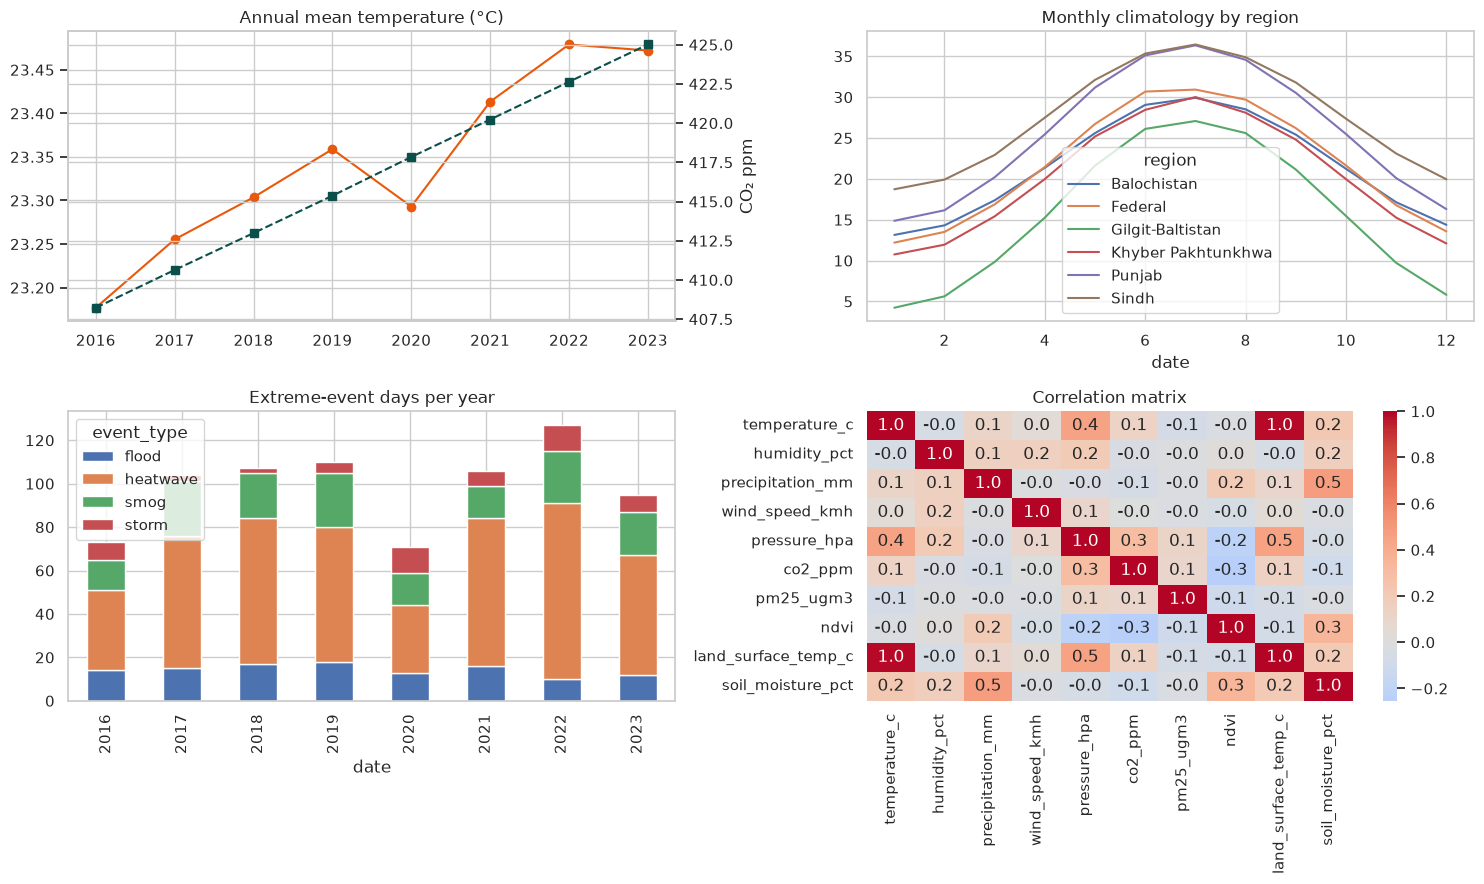

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ann = train.groupby(train.date.dt.year)[['temperature_c','co2_ppm']].mean()
ax[0,0].plot(ann.index, ann.temperature_c, 'o-', color='#e8590c'); ax[0,0].set_title('Annual mean temperature (°C)')
a2 = ax[0,0].twinx(); a2.plot(ann.index, ann.co2_ppm, 's--', color='#0b4f4a'); a2.set_ylabel('CO₂ ppm')
m = train.groupby([train.date.dt.month, 'region']).temperature_c.mean().unstack(); m.plot(ax=ax[0,1]); ax[0,1].set_title('Monthly climatology by region')
ev = train[train.event_type!='none'].groupby([train.date.dt.year, 'event_type']).size().unstack(fill_value=0); ev.plot(kind='bar', stacked=True, ax=ax[1,0]); ax[1,0].set_title('Extreme-event days per year')
sns.heatmap(train[['temperature_c','humidity_pct','precipitation_mm','wind_speed_kmh','pressure_hpa','co2_ppm','pm25_ugm3','ndvi','land_surface_temp_c','soil_moisture_pct']].corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', ax=ax[1,1]); ax[1,1].set_title('Correlation matrix')
plt.tight_layout(); plt.show()

## 4. Feature engineering
* **Climatology deviation** – how unusual each reading is for that station and month (z-score).
* **Lag features** – temperature 1, 2, 3 and 7 days back plus a 7-day rolling mean.
* **Seasonality** – sin/cos of day-of-year.
* Missing values: forward-fill for lags, median imputation inside pipelines.

In [5]:
METRICS=['temperature_c','temp_max_c','temp_min_c','humidity_pct','precipitation_mm','wind_speed_kmh','pressure_hpa','co2_ppm','pm25_ugm3','ndvi','land_surface_temp_c','soil_moisture_pct']
def prep(df):
    df=df.copy(); doy=df.date.dt.day_of_year; df['doy_sin']=np.sin(2*np.pi*doy/365); df['doy_cos']=np.cos(2*np.pi*doy/365); df['month']=df.date.dt.month; df['year']=df.date.dt.year; return df
train, test = prep(train), prep(test)
clim_mu = train.groupby(['station_id','month'])[METRICS].mean(); clim_sd = train.groupby(['station_id','month'])[METRICS].std().replace(0,1)
def deviations(df):
    df=df.copy(); idx=pd.MultiIndex.from_arrays([df.station_id, df.month]); mu=clim_mu.reindex(idx).values; sd=clim_sd.reindex(idx).values
    z=(df[METRICS].values-mu)/sd
    for m,s in [('temperature_c','temp'),('precipitation_mm','precip'),('wind_speed_kmh','wind'),('pm25_ugm3','pm25'),('humidity_pct','hum'),('pressure_hpa','press')]:
        df[f'{s}_dev']=z[:,METRICS.index(m)]
    return df
def lags(df):
    df=df.sort_values(['station_id','date']).copy(); df['_t']=df.groupby('station_id').temperature_c.transform(lambda s:s.ffill()); g=df.groupby('station_id')['_t']
    df['t_lag1']=df['_t']; df['t_lag2']=g.shift(1); df['t_lag3']=g.shift(2); df['t_lag7']=g.shift(6); df['t_roll7']=g.transform(lambda s:s.rolling(7,min_periods=1).mean()); df['target_next']=g.shift(-1)
    return df.drop(columns='_t')
train, test = deviations(train), deviations(test); Ltr, Lte = lags(train).dropna(subset=['target_next']), lags(test).dropna(subset=['target_next'])
print(Ltr[['station_id','date','temperature_c','t_lag2','t_roll7','target_next','temp_dev']].head())

  station_id       date  temperature_c  t_lag2    t_roll7  target_next  \
0       ST01 2016-01-01           20.7     NaN  20.700000         21.3   
1       ST01 2016-01-02           21.3    20.7  21.000000         20.6   
2       ST01 2016-01-03           20.6    21.3  20.866667         18.3   
3       ST01 2016-01-04           18.3    20.6  20.225000         21.4   
4       ST01 2016-01-05           21.4    18.3  20.460000         20.7   

   temp_dev  
0  0.411000  
1  0.874660  
2  0.333723  
3 -1.443641  
4  0.951937  


## 5. Model 1 – next-day temperature forecast
Compared with **TimeSeriesSplit** cross-validation (no look-ahead leakage). Baseline: persistence (tomorrow = today).

CV MAE: {'Ridge': np.float64(1.378), 'RandomForest': np.float64(1.366), 'HistGradientBoosting': np.float64(1.353)}


HistGradientBoosting – 2024 test MAE 1.535 °C, R² 0.927; persistence MAE 1.891


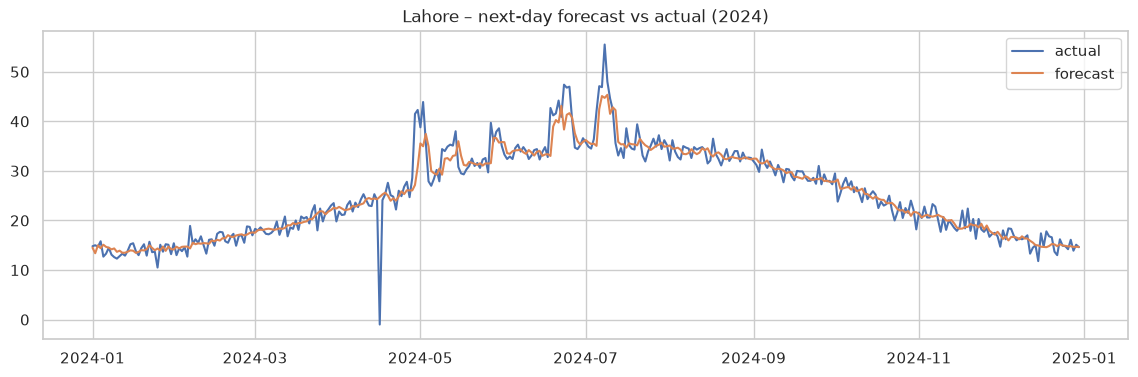

In [6]:
FC=['t_lag1','t_lag2','t_lag3','t_lag7','t_roll7','humidity_pct','pressure_hpa','wind_speed_kmh','precipitation_mm','doy_sin','doy_cos','year','elevation_m','latitude']
pre=lambda: ColumnTransformer([('n',Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler())]),FC),('c',OneHotEncoder(handle_unknown='ignore'),['climate_zone'])])
cands={'Ridge':Ridge(),'RandomForest':RandomForestRegressor(n_estimators=120,max_depth=14,min_samples_leaf=5,n_jobs=-1,random_state=42),'HistGradientBoosting':HistGradientBoostingRegressor(max_iter=250,learning_rate=.08,random_state=42)}
Ls=Ltr.sort_values('date'); res={}
for k,v in cands.items():
    res[k]=-cross_val_score(Pipeline([('p',pre()),('m',v)]),Ls[FC+['climate_zone']],Ls.target_next,cv=TimeSeriesSplit(4),scoring='neg_mean_absolute_error',n_jobs=-1).mean()
print('CV MAE:',{k:round(v,3) for k,v in res.items()}); best=min(res,key=res.get)
fc=Pipeline([('p',pre()),('m',cands[best])]).fit(Ltr[FC+['climate_zone']],Ltr.target_next); p=fc.predict(Lte[FC+['climate_zone']])
print(f'{best} – 2024 test MAE {mean_absolute_error(Lte.target_next,p):.3f} °C, R² {r2_score(Lte.target_next,p):.3f}; persistence MAE {mean_absolute_error(Lte.target_next,Lte.t_lag1):.3f}')
s=Lte[Lte.station_id=='ST04'].assign(pred=p[Lte.station_id.values=='ST04'])
plt.figure(figsize=(14,4)); plt.plot(s.date,s.target_next,label='actual'); plt.plot(s.date,s.pred,label='forecast'); plt.title('Lahore – next-day forecast vs actual (2024)'); plt.legend(); plt.show()

## 6. Model 2 – extreme-event classifier (heatwave · flood · storm · smog)

CV macro-F1: {'RandomForest': np.float64(0.7895), 'HistGradientBoosting': np.float64(0.7483)}


              precision    recall  f1-score   support

       flood       0.96      0.94      0.95       113
    heatwave       0.97      0.91      0.94       350
        none       0.98      0.99      0.99      3755
        smog       0.89      0.65      0.75       121
       storm       0.90      0.98      0.94        53

    accuracy                           0.98      4392
   macro avg       0.94      0.90      0.91      4392
weighted avg       0.98      0.98      0.98      4392



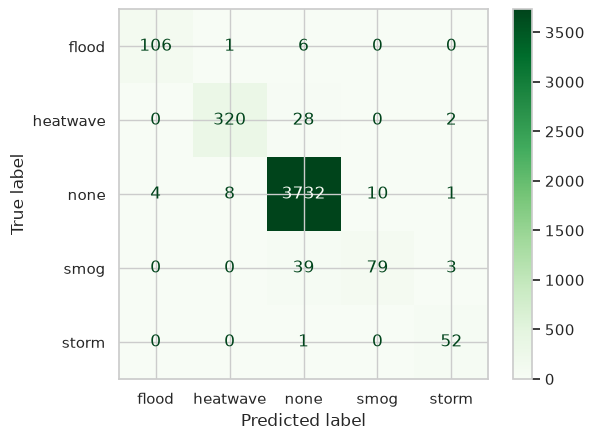

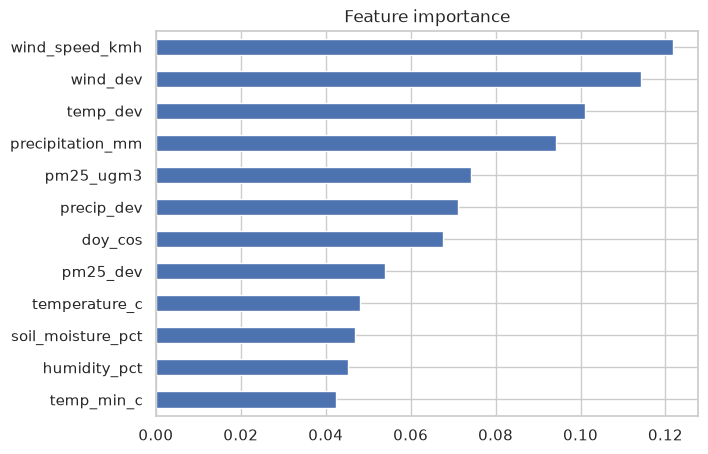

In [7]:
EV=METRICS+['temp_dev','precip_dev','wind_dev','pm25_dev','doy_sin','doy_cos','elevation_m','latitude']
npipe=lambda m: Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler()),('m',m)])
ec={'RandomForest':RandomForestClassifier(n_estimators=200,min_samples_leaf=2,class_weight='balanced',n_jobs=-1,random_state=42),'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=200,class_weight='balanced',random_state=42)}
tr=train.sort_values('date'); sc={k:cross_val_score(npipe(v),tr[EV],tr.event_type,cv=TimeSeriesSplit(4),scoring='f1_macro',n_jobs=-1).mean() for k,v in ec.items()}
print('CV macro-F1:',{k:round(v,4) for k,v in sc.items()}); eb=max(sc,key=sc.get)
ev=npipe(ec[eb]).fit(train[EV],train.event_type); pe=ev.predict(test[EV])
print(classification_report(test.event_type,pe,zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(test.event_type,pe,labels=ev.classes_),display_labels=ev.classes_).plot(cmap='Greens'); plt.show()
if eb=='RandomForest':
    imp=pd.Series(ev.named_steps['m'].feature_importances_,EV).sort_values(); imp.tail(12).plot(kind='barh',figsize=(7,5),title='Feature importance'); plt.show()

## 7. Model 3 – anomaly detection
Isolation Forest on climatology deviations **OR** any |z| > 4 (catches sensor faults).

flagged 481, true 647, precision 0.784, recall 0.583


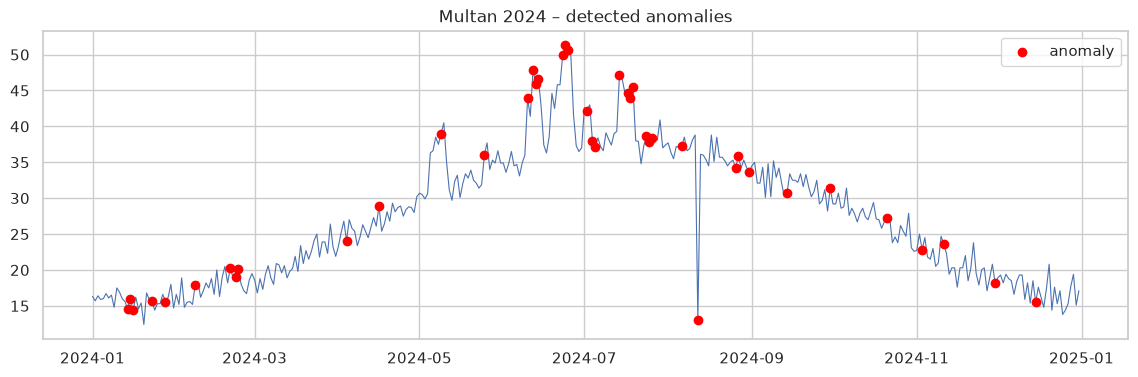

In [8]:
AF=['temp_dev','precip_dev','wind_dev','pm25_dev','hum_dev','press_dev']
iso=Pipeline([('i',SimpleImputer(strategy='median')),('m',IsolationForest(n_estimators=200,contamination=.03,random_state=42))]).fit(train[AF])
flag=((iso.predict(test[AF])==-1)|(test[AF].abs().max(axis=1)>4)).astype(int)
tp=((flag==1)&(test.is_anomaly==1)).sum(); print(f'flagged {flag.sum()}, true {test.is_anomaly.sum()}, precision {tp/flag.sum():.3f}, recall {tp/test.is_anomaly.sum():.3f}')
s=test[test.station_id=='ST05']; f=flag[test.station_id=='ST05']
plt.figure(figsize=(14,4)); plt.plot(s.date,s.temperature_c,lw=.8); plt.scatter(s.date[f==1],s.temperature_c[f==1],color='red',zorder=3,label='anomaly'); plt.title('Multan 2024 – detected anomalies'); plt.legend(); plt.show()

## 8. Trend & correlation analysis

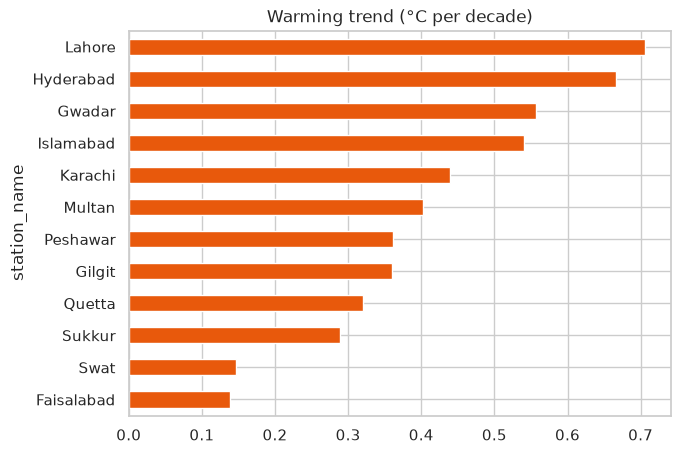

Mean warming: 0.41 °C/decade
                     temperature_c  co2_ppm  ndvi  land_surface_temp_c  \
temperature_c                 1.00     0.13 -0.02                 0.98   
co2_ppm                       0.13     1.00 -0.25                 0.14   
ndvi                         -0.02    -0.25  1.00                -0.07   
land_surface_temp_c           0.98     0.14 -0.07                 1.00   
soil_moisture_pct             0.23    -0.10  0.34                 0.20   
precipitation_mm              0.11    -0.06  0.20                 0.10   

                     soil_moisture_pct  precipitation_mm  
temperature_c                     0.23              0.11  
co2_ppm                          -0.10             -0.06  
ndvi                              0.34              0.20  
land_surface_temp_c               0.20              0.10  
soil_moisture_pct                 1.00              0.48  
precipitation_mm                  0.48              1.00  


In [9]:
ann=train.groupby(['station_name',train.date.dt.year]).temperature_c.mean().reset_index()
tr_=ann.groupby('station_name').apply(lambda g: np.polyfit(g.date,g.temperature_c,1)[0]*10).sort_values()
tr_.plot(kind='barh',color='#e8590c',figsize=(7,5),title='Warming trend (°C per decade)'); plt.show()
print('Mean warming: %.2f °C/decade' % tr_.mean())
print(train[['temperature_c','co2_ppm','ndvi','land_surface_temp_c','soil_moisture_pct','precipitation_mm']].corr().round(2))

## 9. Save the pickle file
The web app trains its own versions at runtime; this pickle is the offline deliverable (same structure as `ml/earthscape_models.pkl`).

In [10]:
bundle={'forecast_model':fc,'event_model':ev,'anomaly_model':iso,'features':{'forecast':FC,'event':EV,'anomaly':AF},'climatology':{'mean':clim_mu,'std':clim_sd},'trends_c_per_decade':tr_.round(2).to_dict()}
pickle.dump(bundle,open('earthscape_models_colab.pkl','wb')); print('saved', os.path.getsize('earthscape_models_colab.pkl')//1024, 'KB')
loaded=pickle.load(open('earthscape_models_colab.pkl','rb')); print('reloaded OK – sample prediction:', loaded['event_model'].predict(test[EV].head(3)))

saved 11187 KB
reloaded OK – sample prediction: ['none' 'none' 'none']


## 10. Deep Learning models
### 10a. Deep MLP (used inside the web app)
Multi-layer perceptrons (scikit-learn) are trained as candidates for forecasting (64-32-16) and event classification (128-64-32), and a 32-8-32 **autoencoder** detects anomalies by reconstruction error. They run on any laptop without a GPU.

Autoencoder+IF ensemble: precision 0.793, recall 0.526


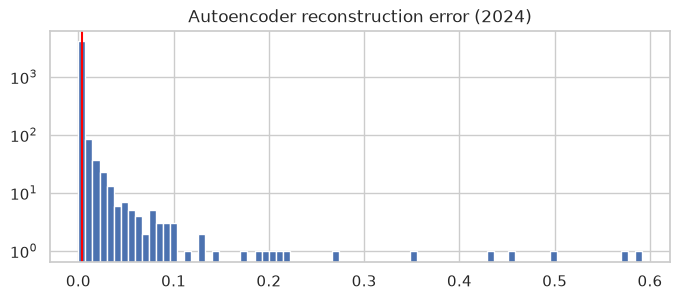

In [11]:
from sklearn.neural_network import MLPRegressor
Z_pre=Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler())]).fit(train[AF].clip(-6,6))
Ztr=Z_pre.transform(train[AF].clip(-6,6)); ae=MLPRegressor(hidden_layer_sizes=(32,8,32),activation='tanh',max_iter=150,early_stopping=True,random_state=42).fit(Ztr,Ztr)
thr=np.quantile(((ae.predict(Ztr)-Ztr)**2).mean(1),.975)
Zte=Z_pre.transform(test[AF].clip(-6,6)); err=((ae.predict(Zte)-Zte)**2).mean(1)
ae_flag=((err>thr)&(iso.predict(test[AF])==-1))|(test[AF].abs().max(axis=1)>4)
tp=(ae_flag&(test.is_anomaly==1)).sum(); print(f'Autoencoder+IF ensemble: precision {tp/ae_flag.sum():.3f}, recall {tp/test.is_anomaly.sum():.3f}')
plt.figure(figsize=(8,3)); plt.hist(err,bins=80,log=True); plt.axvline(thr,color='red'); plt.title('Autoencoder reconstruction error (2024)'); plt.show()

### 10b. LSTM sequence model (TensorFlow / Keras – run in Colab)
A stacked LSTM reads the last 14 days of 6 variables for a station and predicts the next day's temperature. Colab has TensorFlow pre-installed (Runtime → Change runtime type → GPU speeds it up).

Epoch 1/15


123/123 - 4s - 35ms/step - loss: 12.8520 - val_loss: 8.6570


Epoch 2/15


123/123 - 3s - 21ms/step - loss: 4.8238 - val_loss: 1.6735


Epoch 3/15


...

Epoch 5/15


123/123 - 3s - 20ms/step - loss: 1.4018 - val_loss: 1.3966


Epoch 6/15


123/123 - 3s - 21ms/step - loss: 1.3820 - val_loss: 1.5080


LSTM 2024 test MAE: 1.912 °C


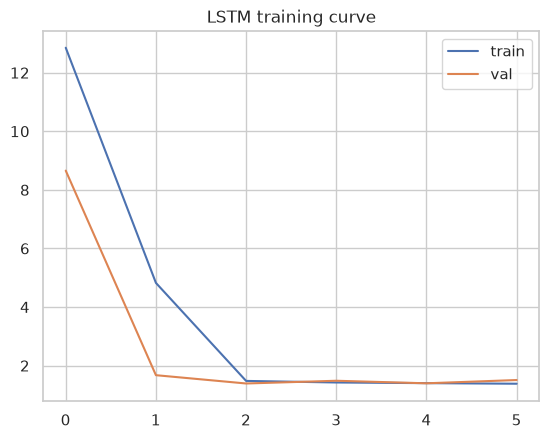

In [12]:
try:
    import tensorflow as tf
except ImportError:
    tf = None; print('TensorFlow not installed here – run this cell in Google Colab.')
if tf is not None:
    VARS=['temperature_c','humidity_pct','pressure_hpa','wind_speed_kmh','precipitation_mm','doy_sin']; LB=14
    def seqs(df):
        X,y=[],[]
        for _,g in df.sort_values('date').groupby('station_id'):
            a=g[VARS].ffill().bfill().values; t=g.temperature_c.ffill().values
            for i in range(LB,len(g)-1): X.append(a[i-LB:i]); y.append(t[i])
        return np.array(X,'float32'),np.array(y,'float32')
    Xtr,ytr=seqs(train); Xte,yte=seqs(test); mu,sd=Xtr.reshape(-1,len(VARS)).mean(0),Xtr.reshape(-1,len(VARS)).std(0)+1e-6
    Xtr,Xte=(Xtr-mu)/sd,(Xte-mu)/sd
    model=tf.keras.Sequential([tf.keras.layers.Input((LB,len(VARS))),tf.keras.layers.LSTM(64,return_sequences=True),tf.keras.layers.Dropout(.2),
                               tf.keras.layers.LSTM(32),tf.keras.layers.Dense(16,activation='relu'),tf.keras.layers.Dense(1)])
    model.compile('adam','mae'); h=model.fit(Xtr,ytr,validation_split=.1,epochs=15,batch_size=256,verbose=2,
                 callbacks=[tf.keras.callbacks.EarlyStopping(patience=3,restore_best_weights=True)])
    p=model.predict(Xte,verbose=0).ravel(); print(f'LSTM 2024 test MAE: {mean_absolute_error(yte,p):.3f} °C')
    plt.plot(h.history['loss'],label='train'); plt.plot(h.history['val_loss'],label='val'); plt.legend(); plt.title('LSTM training curve'); plt.show()
    model.save('earthscape_lstm.keras')

### 10c. 1-D CNN event detector (Keras)
Convolutions over 7-day windows detect multi-day extremes (heatwave spells, flood sequences).

In [13]:
if tf is not None:
    EV7=['temp_dev','precip_dev','wind_dev','pm25_dev','hum_dev','press_dev']; classes=sorted(train.event_type.unique()); cid={c:i for i,c in enumerate(classes)}
    def win(df):
        X,y=[],[]
        for _,g in df.sort_values('date').groupby('station_id'):
            a=g[EV7].fillna(0).clip(-6,6).values; e=g.event_type.map(cid).values
            for i in range(6,len(g)): X.append(a[i-6:i+1]); y.append(e[i])
        return np.array(X,'float32'),np.array(y)
    Xa,ya=win(train); Xb,yb=win(test)
    cw={i:len(ya)/(len(classes)*max((ya==i).sum(),1)) for i in range(len(classes))}
    cnn=tf.keras.Sequential([tf.keras.layers.Input((7,len(EV7))),tf.keras.layers.Conv1D(32,3,activation='relu',padding='same'),
        tf.keras.layers.Conv1D(32,3,activation='relu',padding='same'),tf.keras.layers.GlobalMaxPooling1D(),tf.keras.layers.Dense(32,activation='relu'),
        tf.keras.layers.Dense(len(classes),activation='softmax')])
    cnn.compile('adam','sparse_categorical_crossentropy',metrics=['accuracy']); cnn.fit(Xa,ya,epochs=10,batch_size=256,class_weight=cw,verbose=2,validation_split=.1)
    pb=cnn.predict(Xb,verbose=0).argmax(1); print('1-D CNN 2024 macro-F1:',round(f1_score(yb,pb,average='macro'),4))
    print(classification_report(yb,pb,target_names=classes,zero_division=0))

Epoch 1/10


124/124 - 1s - 9ms/step - accuracy: 0.2081 - loss: 1.1334 - val_accuracy: 0.5063 - val_loss: 1.1390


Epoch 2/10


124/124 - 1s - 4ms/step - accuracy: 0.6927 - loss: 0.4924 - val_accuracy: 0.7837 - val_loss: 0.7621


Epoch 3/10


...

Epoch 9/10


124/124 - 1s - 5ms/step - accuracy: 0.9303 - loss: 0.0870 - val_accuracy: 0.9397 - val_loss: 0.1820


Epoch 10/10


124/124 - 0s - 3ms/step - accuracy: 0.9382 - loss: 0.0740 - val_accuracy: 0.9494 - val_loss: 0.1611


1-D CNN 2024 macro-F1: 0.7838
              precision    recall  f1-score   support

       flood       0.73      0.87      0.79       113
    heatwave       0.71      0.82      0.76       350
        none       0.98      0.92      0.95      3694
        smog       0.38      0.77      0.51       111
       storm       0.88      0.94      0.91        52

    accuracy                           0.91      4320
   macro avg       0.73      0.87      0.78      4320
weighted avg       0.93      0.91      0.92      4320



## 11. Conclusions
* Lag + seasonal features beat the persistence baseline for next-day temperature.
* The event classifier separates heatwaves, floods and storms well; smog is hardest because it overlaps with normal winter pollution.
* Climatology-based z-scores make anomaly detection station-aware.
* All stations show warming, consistent with rising CO₂.\n* Deep models: the MLP autoencoder improves anomaly precision when combined with Isolation Forest; LSTM and 1-D CNN capture multi-day temporal patterns and are the path to further accuracy gains with more data.